<a href="https://colab.research.google.com/github/Paxlawa/Labu/blob/main/%D0%9B%D0%A06_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [3]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [15]:
print(df['gender'].value_counts(dropna=False))

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [16]:
print(df['smoking_history'].value_counts(dropna=False))

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [17]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [18]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


In [19]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


In [20]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [21]:
df.duplicated().sum()

np.int64(3854)

In [22]:
df.drop_duplicates(inplace=True)

In [23]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [24]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


<Axes: xlabel='diabetes', ylabel='count'>

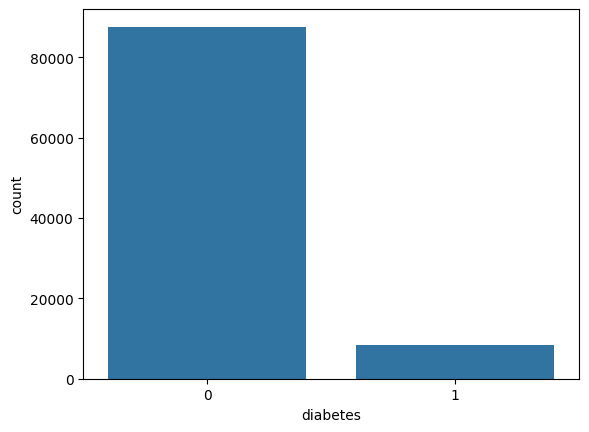

In [25]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

In [26]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [27]:
X = df.drop(columns='diabetes')
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(76916, 8) (19230, 8)
diabetes
0    0.911774
1    0.088226
Name: proportion, dtype: float64
diabetes
0    0.911804
1    0.088196
Name: proportion, dtype: float64


In [28]:
cat_cols = ['gender', 'smoking_history']

X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print(X_train_enc.shape, X_test_enc.shape)
print(list(X_train_enc.columns) == list(X_test_enc.columns))  # має бути True

(76916, 13) (19230, 13)
True


In [29]:
X_train_enc.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.417143,0.000182,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493090,0.013490,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [31]:
corr_with_target = X_train_enc.corrwith(y_train).sort_values(ascending=False)
print(corr_with_target)

blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
dtype: float64


In [32]:
corr_matrix = X_train_enc.corr()

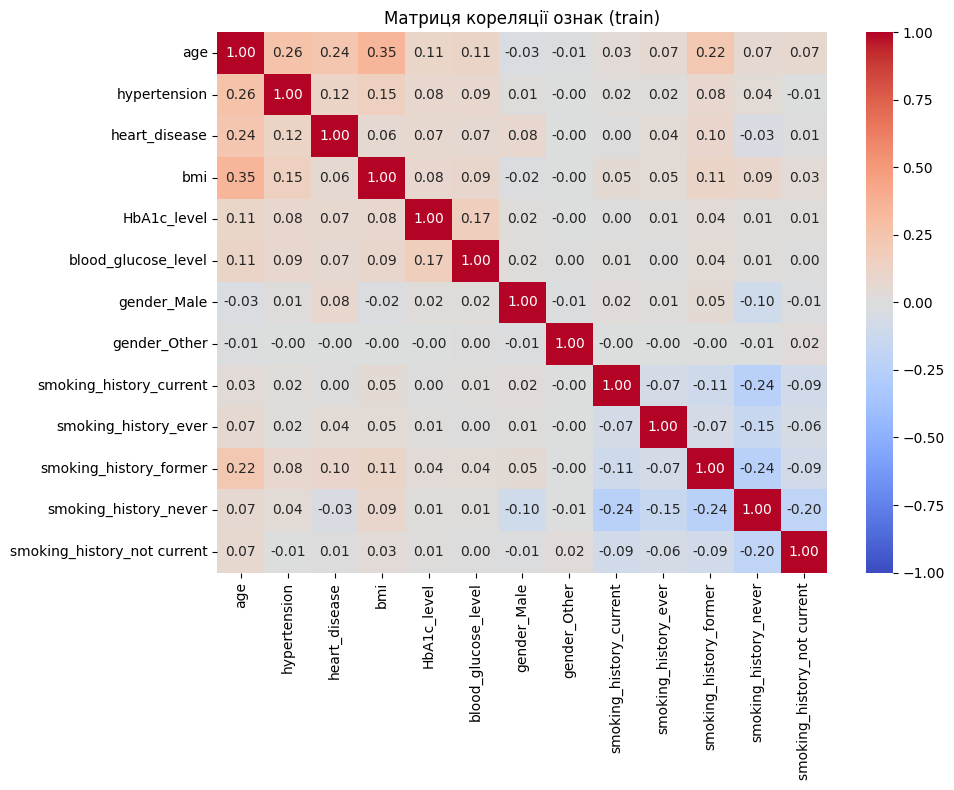

In [33]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Матриця кореляції ознак (train)')
plt.tight_layout()
plt.show()

In [34]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

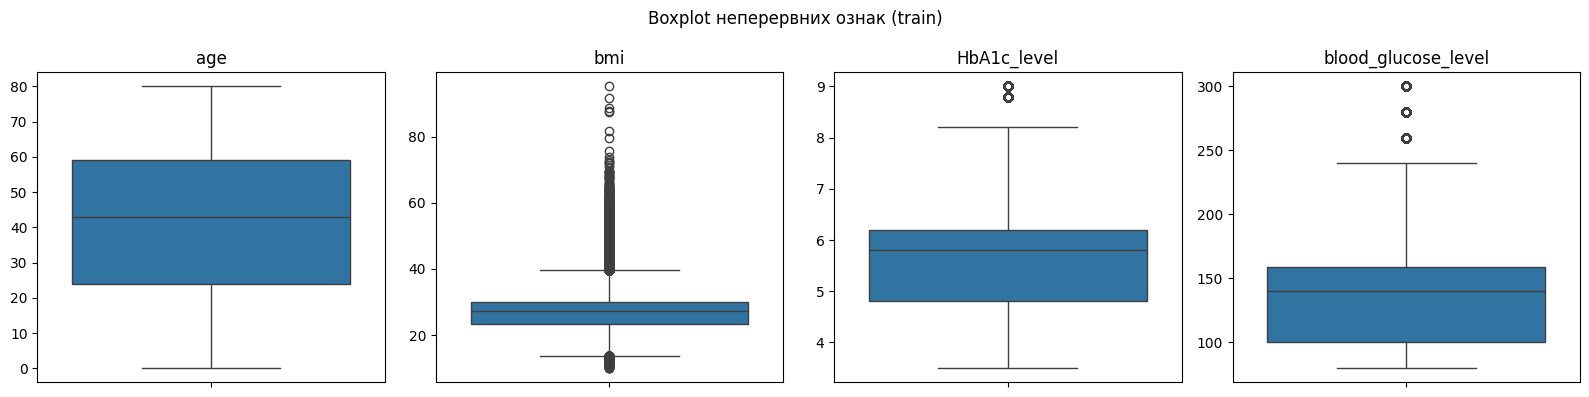

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel('')
plt.suptitle('Boxplot неперервних ознак (train)')
plt.tight_layout()
plt.show()

In [37]:
assert X_train_enc.shape[0] == y_train.shape[0]
assert X_test_enc.shape[0] == y_test.shape[0]
print(X_train_enc.shape, y_train.shape, X_test_enc.shape, y_test.shape)

(76916, 13) (76916,) (19230, 13) (19230,)


In [38]:
skewness = X_train[continuous_cols].skew().sort_values(ascending=False)
print(skewness)

bmi                    1.005016
blood_glucose_level    0.830778
HbA1c_level           -0.055651
age                   -0.061461
dtype: float64


In [39]:
print('Пропуски в X_train:')
print(X_train.isna().sum())
print('Всього:', X_train.isna().sum().sum())

print('\nПропуски в X_test:')
print(X_test.isna().sum())
print('Всього:', X_test.isna().sum().sum())

Пропуски в X_train:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
dtype: int64
Всього: 0

Пропуски в X_test:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
dtype: int64
Всього: 0


In [40]:
scaler = StandardScaler()

In [41]:
X_train_scaled = scaler.fit_transform(X_train_enc)
X_test_scaled = scaler.transform(X_test_enc)

print(X_train_scaled.shape, X_test_scaled.shape)

(76916, 13) (19230, 13)


In [42]:
print('До SMOTE:')
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print('\nПісля SMOTE:')
print(y_train_res.value_counts())

До SMOTE:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


In [43]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42),
}

print(list(models.keys()))

['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC']


In [44]:
from sklearn.svm import LinearSVC
models['SVC'] = LinearSVC(random_state=42, max_iter=5000)

===== LogisticRegression =====
              precision    recall  f1-score   support

           0      0.987     0.886     0.934     17534
           1      0.426     0.879     0.574      1696

    accuracy                          0.885     19230
   macro avg      0.707     0.882     0.754     19230
weighted avg      0.938     0.885     0.902     19230



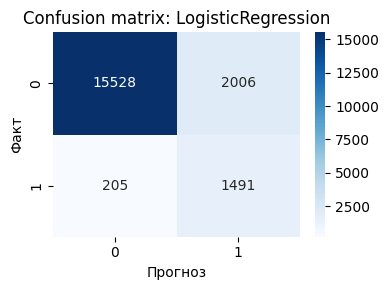

===== RidgeClassifier =====
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.433     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.710     0.882     0.757     19230
weighted avg      0.938     0.888     0.904     19230



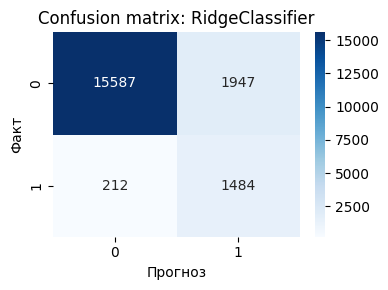

===== SGDClassifier =====
              precision    recall  f1-score   support

           0      0.990     0.856     0.918     17534
           1      0.379     0.910     0.535      1696

    accuracy                          0.860     19230
   macro avg      0.684     0.883     0.726     19230
weighted avg      0.936     0.860     0.884     19230



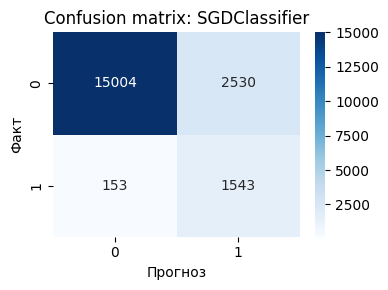

===== SVC =====
              precision    recall  f1-score   support

           0      0.987     0.885     0.933     17534
           1      0.426     0.882     0.575      1696

    accuracy                          0.885     19230
   macro avg      0.707     0.884     0.754     19230
weighted avg      0.938     0.885     0.902     19230



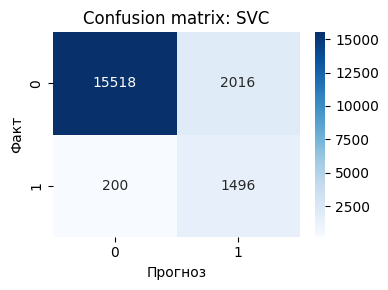

In [45]:
results = {}

for name, model in models.items():

    model.fit(X_train_res, y_train_res)

    y_pred = model.predict(X_test_scaled)
    results[name] = y_pred


    print(f'===== {name} =====')
    print(classification_report(y_test, y_pred, digits=3))


    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['0', '1'], yticklabels=['0', '1'])
    plt.title(f'Confusion matrix: {name}')
    plt.xlabel('Прогноз')
    plt.ylabel('Факт')
    plt.tight_layout()
    plt.show()

In [46]:
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear'],
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0, 100.0],
    },
    'SGDClassifier': {
        'loss': ['hinge', 'log_loss', 'modified_huber'],
        'penalty': ['l2', 'l1', 'elasticnet'],
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf'],
    },
}

In [50]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [51]:
pipelines = {
    name: Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('clf', clone(model)),
    ])
    for name, model in models.items()
}
print(list(pipelines.keys()))

['LogisticRegression', 'RidgeClassifier', 'SGDClassifier', 'SVC']


In [52]:
best_models = {}
best_scores = {}

In [53]:
def run_search(name):
    grid = {f'clf__{k}': v for k, v in param_grids[name].items()}

    search = HalvingGridSearchCV(
        pipelines[name],
        param_grid=grid,
        scoring='f1',
        cv=3,
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1,
    )


    search.fit(X_train_enc, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print(f'===== {name} =====')
    print('Найкращі параметри:', search.best_params_)
    print(f'Найкращий F1 (CV): {search.best_score_:.4f}')

    y_pred = search.best_estimator_.predict(X_test_enc)
    print(classification_report(y_test, y_pred, digits=3))

In [54]:
run_search('LogisticRegression')

===== LogisticRegression =====
Найкращі параметри: {'clf__C': 0.01, 'clf__solver': 'lbfgs'}
Найкращий F1 (CV): 0.6864
              precision    recall  f1-score   support

           0      0.987     0.886     0.934     17534
           1      0.427     0.880     0.575      1696

    accuracy                          0.885     19230
   macro avg      0.707     0.883     0.754     19230
weighted avg      0.938     0.885     0.902     19230



In [55]:
run_search('RidgeClassifier')

===== RidgeClassifier =====
Найкращі параметри: {'clf__alpha': 100.0}
Найкращий F1 (CV): 0.6705
              precision    recall  f1-score   support

           0      0.987     0.889     0.935     17534
           1      0.433     0.875     0.579      1696

    accuracy                          0.888     19230
   macro avg      0.710     0.882     0.757     19230
weighted avg      0.938     0.888     0.904     19230



In [56]:
run_search('SGDClassifier')

===== SGDClassifier =====
Найкращі параметри: {'clf__loss': 'hinge', 'clf__penalty': 'elasticnet'}
Найкращий F1 (CV): 0.6151
              precision    recall  f1-score   support

           0      0.990     0.857     0.919     17534
           1      0.382     0.909     0.538      1696

    accuracy                          0.862     19230
   macro avg      0.686     0.883     0.728     19230
weighted avg      0.936     0.862     0.885     19230



In [58]:
pd.Series(best_scores).sort_values(ascending=False)

,0
LogisticRegression,0.686448
RidgeClassifier,0.670486
SGDClassifier,0.615138


In [59]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]

print('Найкраща модель:', best_name)
print(f'Середній F1 (CV): {best_scores[best_name]:.4f}')

Найкраща модель: LogisticRegression
Середній F1 (CV): 0.6864


In [60]:
y_pred = best_model.predict(X_test_enc)
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.987     0.886     0.934     17534
           1      0.427     0.880     0.575      1696

    accuracy                          0.885     19230
   macro avg      0.707     0.883     0.754     19230
weighted avg      0.938     0.885     0.902     19230



In [61]:
sample_idx = X_test_enc.sample(n=10, random_state=42).index

In [62]:
y_pred_sample = best_model.predict(X_test_enc.loc[sample_idx])

comparison = pd.DataFrame({
    'індекс': sample_idx,
    'істинний клас': y_test.loc[sample_idx].values,
    'передбачений клас': y_pred_sample,
})
comparison['збіг'] = comparison['істинний клас'] == comparison['передбачений клас']

comparison

,індекс,істинний клас,передбачений клас,збіг
0,36061,0,0,True
1,29824,0,0,True
2,29668,0,1,False
3,11816,0,0,True
4,99242,0,0,True
5,26718,0,0,True
6,53059,0,0,True
7,69294,0,0,True
8,8912,0,1,False
9,37072,0,0,True
